# Assignment 1 — training pipeline


The idea: a company has a few shared EV chargers for its employees. When someone leaves their car plugged in for half a day, another one can't charge. I want to predict, right when a car gets plugged in, whether the session will last more than 4 hours, so the company can send that person a reminder.

In this notebook I clean the data, build the target, split it by time, create the features, train the same logistic regression three ways, pick a decision threshold based on a business cost, and save everything the dashboard needs.

## 1. Setup

In [181]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA_PATH = Path("data/station_data_dataverse.csv")
ARTIFACTS_DIR = Path("artifacts")
ARTIFACTS_DIR.mkdir(exist_ok=True)

LONG_SESSION_HOURS = 4   # business definition of "blocking" a charger
SEED = 42

### Plot helper

`main.py` runs this notebook as a normal Python script. In a script, `plt.show()` opens a window and waits until you close it, which would freeze the training. So I made a small helper: inside the notebook it shows the plot as usual, and when it runs as a script it only saves the image in `artifacts/figures/`. The saved images are also handy for the report.

In [182]:
import matplotlib
try:
    get_ipython()          
    IN_NOTEBOOK = True
except NameError:
    IN_NOTEBOOK = False
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  
import matplotlib.pyplot as plt

FIG_DIR = ARTIFACTS_DIR / "figures"
FIG_DIR.mkdir(exist_ok=True)

def show_and_save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120)
    if IN_NOTEBOOK:
        plt.show()
    else:
        plt.close(fig)

## 2. Load the data and fix the dates

When I opened the file I noticed the years were wrong: dates look like `0014-11-18` instead of `2014-11-18`. I need real dates because the whole project depends on time order (the split and the driver history), so I fix that first and then sort the sessions by start time.

In [183]:
df = pd.read_csv(DATA_PATH)
print("shape:", df.shape)

# '0014-...' -> '2014-...'
for col in ["created", "ended"]:
    df[col] = pd.to_datetime(df[col].str.replace(r"^00", "20", regex=True))

# Sort by start time: the split and the history features assume chronological order
df = df.sort_values("created").reset_index(drop=True)
print("from", df["created"].min(), "to", df["created"].max())

shape: (3395, 24)
from 2014-11-18 15:01:17 to 2015-10-04 12:44:59


## 3. Target

A session counts as "blocking" if it lasts more than 4 hours (half a working day). The target is 1 in that case and 0 otherwise. I only use the duration to build the target, it never goes into the model as a feature.

In [184]:
df["target"] = (df["chargeTimeHrs"] > LONG_SESSION_HOURS).astype(int)
print(df["target"].value_counts())
print(f"share of long sessions: {df['target'].mean():.3f}")

target
0    3016
1     379
Name: count, dtype: int64
share of long sessions: 0.112


### How long do sessions last?

Quick look at the durations with the 4-hour line on top, to see how rare the long sessions actually are.

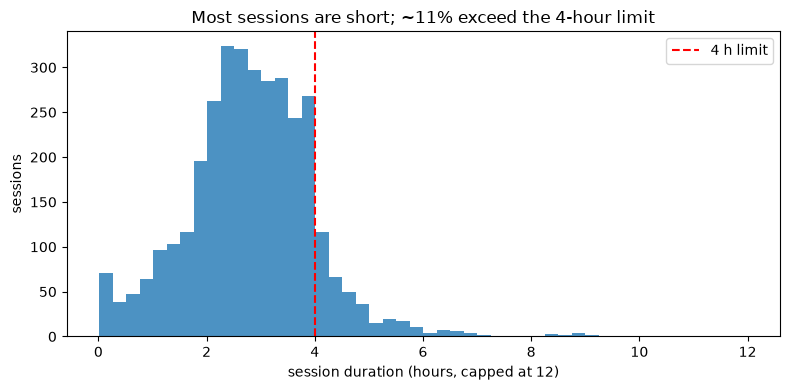

In [185]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["chargeTimeHrs"].clip(upper=12), bins=48, alpha=0.8)
ax.axvline(LONG_SESSION_HOURS, color="red", linestyle="--", label=f"{LONG_SESSION_HOURS} h limit")
ax.set_xlabel("session duration (hours, capped at 12)")
ax.set_ylabel("sessions")
ax.set_title("Most sessions are short; ~11% exceed the 4-hour limit")
ax.legend()
show_and_save(fig, "01_duration_distribution")

## 4. Columns I can't use (leakage)

The prediction happens when the car is plugged in. Some columns only exist once the session is over: energy delivered, cost, end time and the duration itself. If I let the model see them it would basically be cheating, so I write them down here and none of the features below use them.

In [186]:
LEAKAGE_COLS = [
    "kwhTotal",       # energy delivered: known at the end
    "dollars",        # cost: known at the end
    "ended",          # end timestamp
    "endTime",        # end hour
    "chargeTimeHrs",  # duration: this IS the target
]
print("excluded as features:", LEAKAGE_COLS)

excluded as features: ['kwhTotal', 'dollars', 'ended', 'endTime', 'chargeTimeHrs']


## 5. Split by time: train / validation / test (60 / 20 / 20)

In real life the company would train on past sessions and use the model on new ones. A random split would mix future sessions into training and make the results look better than they are. Since the rows are already sorted by date, the oldest 60% go to train, the next 20% to validation (to choose C, the learning rate and the threshold) and the most recent 20% to test, which I only use once at the very end.

In [187]:
n = len(df)
train_end = int(0.6 * n)
val_end = int(0.8 * n)

df["split"] = "train"
df.loc[train_end:val_end - 1, "split"] = "val"
df.loc[val_end:, "split"] = "test"

summary = df.groupby("split", sort=False).agg(
    sessions=("target", "size"),
    long_sessions=("target", "sum"),
    long_share=("target", "mean"),
    first_date=("created", "min"),
    last_date=("created", "max"),
)
print(summary)

       sessions  long_sessions  long_share          first_date  \
split                                                            
train      2037            212    0.104075 2014-11-18 15:01:17   
val         679             87    0.128130 2015-08-08 10:43:19   
test        679             80    0.117820 2015-09-09 13:17:32   

                last_date  
split                      
train 2015-08-07 18:57:44  
val   2015-09-09 12:45:40  
test  2015-10-04 12:44:59  


### Sessions per month

This shows where each split falls in time. The program grew a lot during the year, which is why validation and test only cover about a month each even though they have the same number of rows.

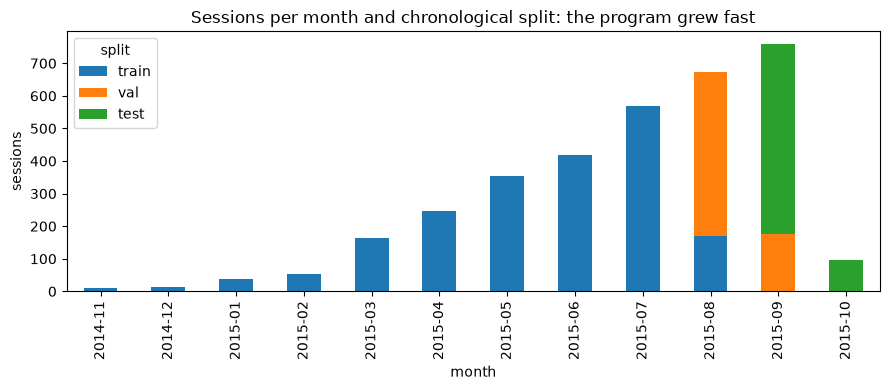

In [188]:
monthly = df.groupby([df["created"].dt.to_period("M"), "split"]).size().unstack(fill_value=0)
monthly = monthly[["train", "val", "test"]]
fig, ax = plt.subplots(figsize=(9, 4))
monthly.plot(kind="bar", stacked=True, ax=ax)
ax.set_xlabel("month")
ax.set_ylabel("sessions")
ax.set_title("Sessions per month and chronological split: the program grew fast")
show_and_save(fig, "02_sessions_per_month_split")

## 6. Features: when the session starts

I don't put the hour in as a plain number. Logistic regression is linear, so it could only learn later = more likely or later = less likely, and the real pattern goes up and down during the day. Instead I group the hours into bands and one-hot encode them.

In [189]:
def hour_band(h):
    if h < 9:   return "early"
    if h < 12:  return "morning"
    if h < 15:  return "midday"
    if h < 18:  return "afternoon"
    return "evening"

df["hour_band"] = df["startTime"].apply(hour_band)
df["is_weekend"] = df["weekday"].isin(["Sat", "Sun"]).astype(int)

time_feats = pd.get_dummies(df["hour_band"], prefix="hour", dtype=int, drop_first=True)
time_feats["is_weekend"] = df["is_weekend"]

## 7. Features: facility and driver profile

`facilityType` comes as 1, 2, 3, 4, but those are labels, not amounts (type 4 isn't "twice" type 2), so I one-hot encode it too. 

In [190]:
profile_feats = pd.get_dummies(df["facilityType"], prefix="facility", dtype=int, drop_first=True)
profile_feats["manager_vehicle"] = df["managerVehicle"]
profile_feats["reported_zip"] = df["reportedZip"]

## 8. Features: distance and the missing flag

About a third of the sessions have no distance. Drivers with a missing distance have more long sessions than the rest, so the fact that it's missing is useful by itself and I keep it as a flag. For the distance column I fill the gaps with the median, calculated on train only so validation and test don't leak into it.

In [191]:
train_mask = df["split"] == "train"
distance_median = df.loc[train_mask, "distance"].median()   # train only

distance_feats = pd.DataFrame({
    "distance_missing": df["distance"].isna().astype(int),
    "distance": df["distance"].fillna(distance_median),
})

## 9. Features: the driver's own history

The common-sense one: if someone usually leaves their car all morning, they'll probably do it again. For every session I look only at that driver's previous sessions: how many they had, what share of them were long, and their average duration. The shift is the important part, it makes sure a session never sees itself or anything after it. New drivers with no history get the training average.

In [192]:
by_user = df.groupby("userId")
prev_sessions = by_user.cumcount()
prev_long_share = by_user["target"].transform(lambda s: s.shift().expanding().mean())
prev_mean_hours = by_user["chargeTimeHrs"].transform(lambda s: s.shift().expanding().mean())

# New drivers have no history: use the training average (cold start)
train_long_share = df.loc[train_mask, "target"].mean()
train_mean_hours = df.loc[train_mask, "chargeTimeHrs"].mean()

history_feats = pd.DataFrame({
    "user_prev_sessions": np.log1p(prev_sessions),
    "user_prev_long_share": prev_long_share.fillna(train_long_share),
    "user_prev_mean_hours": prev_mean_hours.fillna(train_mean_hours),
})

### Do start time and facility actually matter?

Before trusting these features I want to see the share of long sessions per group. I only use train here, so I'm not peeking at the future. The red line is the overall average.

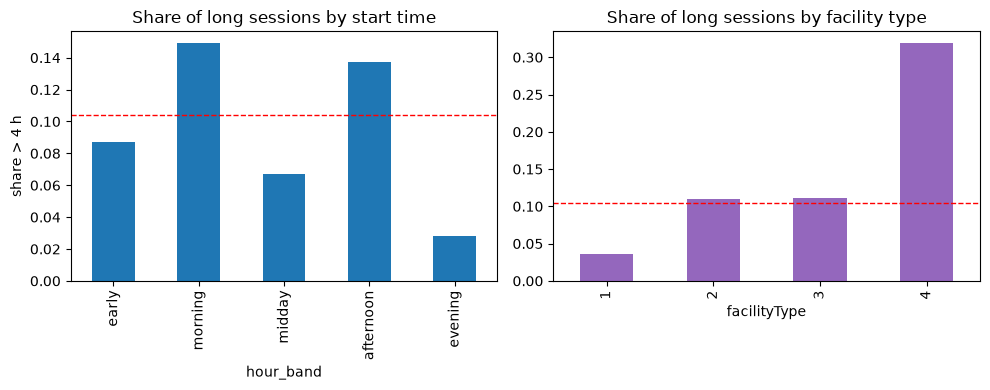

In [193]:
tr = df[df["split"] == "train"]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
(tr.groupby("hour_band")["target"].mean()
   .reindex(["early", "morning", "midday", "afternoon", "evening"])
   .plot(kind="bar", ax=axes[0]))
axes[0].set_title("Share of long sessions by start time")
axes[0].set_ylabel("share > 4 h")
tr.groupby("facilityType")["target"].mean().plot(kind="bar", ax=axes[1], color="tab:purple")
axes[1].set_title("Share of long sessions by facility type")
for a in axes:
    a.axhline(tr["target"].mean(), color="red", linestyle="--", linewidth=1)  # average
show_and_save(fig, "03_long_share_by_feature")

## 10. Put all the features together

I also keep track of which columns belong to which group, so later I can remove one group at a time and see how much it really helps.

In [194]:
FEATURE_GROUPS = {
    "time": list(time_feats.columns),
    "profile": list(profile_feats.columns),
    "distance": list(distance_feats.columns),
    "history": list(history_feats.columns),
}
X_all = pd.concat([time_feats, profile_feats, distance_feats, history_feats], axis=1)
FEATURE_NAMES = list(X_all.columns)
print(f"{len(FEATURE_NAMES)} features:", FEATURE_GROUPS)

15 features: {'time': ['hour_early', 'hour_evening', 'hour_midday', 'hour_morning', 'is_weekend'], 'profile': ['facility_2', 'facility_3', 'facility_4', 'manager_vehicle', 'reported_zip'], 'distance': ['distance_missing', 'distance'], 'history': ['user_prev_sessions', 'user_prev_long_share', 'user_prev_mean_hours']}


## 11. Split into arrays and scale

The scaler puts every column on the same scale (mean 0, std 1). The PyTorch models need this: distance goes up to around 40 while the one-hot columns are 0/1, and with such different scales gradient descent struggles to converge. All three models use exactly these arrays, which is what makes the comparison fair.

In [195]:
from sklearn.preprocessing import StandardScaler

def take(split):
    mask = df["split"] == split
    return X_all[mask].to_numpy(dtype=float), df.loc[mask, "target"].to_numpy()

X_train_raw, y_train = take("train")
X_val_raw, y_val = take("val")
X_test_raw, y_test = take("test")

scaler = StandardScaler().fit(X_train_raw)   # learn mean/std on train ONLY
X_train = scaler.transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)
print(X_train.shape, X_val.shape, X_test.shape)

(2037, 15) (679, 15) (679, 15)


## 12. How I'm going to measure the models

Accuracy is useless here: predicting "never long" would already get  around 89%. I use three metrics that work on the predicted probabilities, so I don't need a threshold yet:
- **log loss**: how wrong the probabilities are (lower is better)
- **ROC AUC**: how often a long session gets a higher probability than a short one 
- **PR AUC**: how well the model finds the long sessions without too many false alarms, the most useful one when positives are rare

The threshold comes later, from the business cost.

In [196]:
from sklearn.metrics import log_loss, roc_auc_score, average_precision_score

def evaluate_probs(y_true, probs):
    """Threshold-free metrics, computed the same way for every model."""
    return {
        "log_loss": log_loss(y_true, probs, labels=[0, 1]),
        "roc_auc": roc_auc_score(y_true, probs),
        "pr_auc": average_precision_score(y_true, probs),
    }

## 13. Naive baseline

In [197]:
baseline_prob = y_train.mean()
baseline_val = np.full(len(y_val), baseline_prob)

print(f"baseline probability: {baseline_prob:.3f}")
print("baseline on validation:",
      {k: round(v, 3) for k, v in evaluate_probs(y_val, baseline_val).items()})

baseline probability: 0.104
baseline on validation: {'log_loss': 0.386, 'roc_auc': 0.5, 'pr_auc': 0.128}


## 14. Model 1: scikit-learn logistic regression

The only thing I tune is the regularization strength "C". A small C means more regularization. I try four values, keep the one with the best PR AUC on validation , and save the model so the dashboard can load it without retraining.

In [198]:
from sklearn.linear_model import LogisticRegression
import joblib

# Tune only the regularization strength, on validation
results = []
for C in [0.01, 0.1, 1.0, 10.0]:
    m = LogisticRegression(C=C, max_iter=1000).fit(X_train, y_train)
    results.append({"C": C, **evaluate_probs(y_val, m.predict_proba(X_val)[:, 1])})
print(pd.DataFrame(results).round(4))

best_C = max(results, key=lambda r: r["pr_auc"])["C"]
print("best C:", best_C)

sk_model = LogisticRegression(C=best_C, max_iter=1000).fit(X_train, y_train)
joblib.dump(sk_model, ARTIFACTS_DIR / "sklearn_model.joblib")

# Coefficients: features are standardized, so their sizes are comparable
coefs = pd.Series(sk_model.coef_[0], index=FEATURE_NAMES).sort_values()
print(coefs.round(3))

       C  log_loss  roc_auc  pr_auc
0   0.01    0.3289   0.7777  0.3832
1   0.10    0.3226   0.7811  0.3893
2   1.00    0.3240   0.7816  0.3862
3  10.00    0.3307   0.7819  0.3867
best C: 0.1
hour_evening           -0.634
hour_midday            -0.314
is_weekend             -0.279
reported_zip           -0.165
distance_missing       -0.023
distance                0.024
hour_morning            0.038
hour_early              0.064
facility_4              0.091
manager_vehicle         0.107
user_prev_sessions      0.119
facility_2              0.184
user_prev_mean_hours    0.218
facility_3              0.364
user_prev_long_share    0.426
dtype: float64


## 15. Model 2: manual PyTorch loop, preparation

For PyTorch to give the same answer as scikit-learn it has to minimise exactly the same thing. scikit-learn doesn't only minimise the BCE, it also adds an L2 penalty on the weights . My loop uses the mean error, so I divide the penalty by the number of rows.

In [199]:
import torch

torch.manual_seed(SEED)
Xtr = torch.tensor(X_train, dtype=torch.float32)
ytr = torch.tensor(y_train, dtype=torch.float32)
Xva = torch.tensor(X_val, dtype=torch.float32)
Xte = torch.tensor(X_test, dtype=torch.float32)

# Same L2 penalty as sklearn's C, rescaled because we use the MEAN loss, not the sum
l2_lambda = 1 / (2 * best_C * len(y_train))
print("l2_lambda:", l2_lambda)

def bce_loss(y_pred, y):
    y_pred = y_pred.clamp(1e-7, 1 - 1e-7)   # never take log(0)
    return -(y * torch.log(y_pred) + (1 - y) * torch.log(1 - y_pred)).mean()

l2_lambda: 0.002454590083456063


In [200]:
def train_manual(lr, n_epochs=2000):
    w = torch.zeros(Xtr.shape[1], requires_grad=True)
    b = torch.zeros(1, requires_grad=True)
    loss_history = []

    for epoch in range(n_epochs):
        y_pred = torch.sigmoid(Xtr @ w + b)                        # 1. forward
        loss = bce_loss(y_pred, ytr) + l2_lambda * (w ** 2).sum()  # 2. loss (+ L2 on w only)
        loss.backward()                                            # 3. gradients

        with torch.no_grad():                                      # 4. manual update
            w -= lr * w.grad
            b -= lr * b.grad
        w.grad.zero_()
        b.grad.zero_()

        loss_history.append(loss.item())
    return w.detach(), b.detach(), loss_history

lr_results = []
for lr in [0.01, 0.1, 0.5, 1.0]:
    w, b, hist = train_manual(lr)
    with torch.no_grad():
        p_val = torch.sigmoid(Xva @ w + b).numpy()
    lr_results.append({"lr": lr, "final_train_loss": hist[-1], **evaluate_probs(y_val, p_val)})
print(pd.DataFrame(lr_results).round(4))

best_lr_manual = min(lr_results, key=lambda r: r["final_train_loss"])["lr"]
print("chosen lr:", best_lr_manual)
w_manual, b_manual, manual_loss_history = train_manual(best_lr_manual)
torch.save({"w": w_manual, "b": b_manual}, ARTIFACTS_DIR / "manual_torch_model.pt")

     lr  final_train_loss  log_loss  roc_auc  pr_auc
0  0.01            0.2965    0.3322   0.7777  0.3808
1  0.10            0.2887    0.3226   0.7813  0.3903
2  0.50            0.2887    0.3226   0.7811  0.3893
3  1.00            0.2887    0.3226   0.7811  0.3893
chosen lr: 1.0


## 16. Does the manual loop match scikit-learn?

Coefficients side by side. If I set up the loss correctly, the differences should be tiny.

In [201]:
coef_compare = pd.DataFrame(
    {"sklearn": sk_model.coef_[0], "manual_torch": w_manual.numpy()},
    index=FEATURE_NAMES,
)
coef_compare["difference"] = coef_compare["manual_torch"] - coef_compare["sklearn"]
print(coef_compare.round(4))
print("intercept  sklearn:", sk_model.intercept_[0].round(4), " manual:", round(b_manual.item(), 4))

                      sklearn  manual_torch  difference
hour_early             0.0644        0.0639     -0.0004
hour_evening          -0.6342       -0.6334      0.0008
hour_midday           -0.3137       -0.3141     -0.0004
hour_morning           0.0376        0.0370     -0.0006
is_weekend            -0.2785       -0.2814     -0.0029
facility_2             0.1836        0.1827     -0.0009
facility_3             0.3636        0.3632     -0.0004
facility_4             0.0907        0.0906     -0.0002
manager_vehicle        0.1070        0.1075      0.0005
reported_zip          -0.1650       -0.1673     -0.0022
distance_missing      -0.0231       -0.0248     -0.0017
distance               0.0244        0.0243     -0.0001
user_prev_sessions     0.1188        0.1187     -0.0001
user_prev_long_share   0.4264        0.4267      0.0003
user_prev_mean_hours   0.2178        0.2173     -0.0004
intercept  sklearn: -2.5127  manual: -2.5126


## 17. Model 3: standard PyTorch workflow (nn.Module + torch.optim)

This version uses PyTorch's standard approach. The model learns the weights and bias, while Adam updates them during training. I added the L2 penalty manually to keep it consistent with scikit-learn. I also tested smaller learning rates because Adam works differently.

In [202]:
import torch.nn as nn

def build_model(n_features):
    # nn.Linear holds w and b; Sigmoid turns the output into a probability
    return nn.Sequential(nn.Linear(n_features, 1), nn.Sigmoid())

def train_standard(lr, n_epochs=2000):
    torch.manual_seed(SEED)
    model = build_model(Xtr.shape[1])
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCELoss()
    loss_history = []

    for epoch in range(n_epochs):
        optimizer.zero_grad()                       # replaces .grad.zero_()
        y_pred = model(Xtr).squeeze(-1)
        # same L2 penalty as sklearn, on the weights only (not the bias)
        loss = loss_fn(y_pred, ytr) + l2_lambda * (model[0].weight ** 2).sum()
        loss.backward()
        optimizer.step()                            # replaces the manual no_grad() update
        loss_history.append(loss.item())
    return model, loss_history

std_results = []
for lr in [0.001, 0.01, 0.1]:
    model, hist = train_standard(lr)
    with torch.no_grad():
        p_val = model(Xva).squeeze(-1).numpy()
    std_results.append({"lr": lr, "final_train_loss": hist[-1], **evaluate_probs(y_val, p_val)})
print(pd.DataFrame(std_results).round(4))

best_lr_std = min(std_results, key=lambda r: r["final_train_loss"])["lr"]
print("chosen lr:", best_lr_std)
std_model, std_loss_history = train_standard(best_lr_std)
torch.save(std_model.state_dict(), ARTIFACTS_DIR / "standard_torch_model.pt")

      lr  final_train_loss  log_loss  roc_auc  pr_auc
0  0.001            0.3280    0.3659   0.7812  0.3846
1  0.010            0.2887    0.3226   0.7811  0.3893
2  0.100            0.2887    0.3224   0.7818  0.3907
chosen lr: 0.01


### Loss curves

Like in class: both PyTorch versions should go down and flatten at the same value. They take different paths because one is plain gradient descent and the other is Adam.

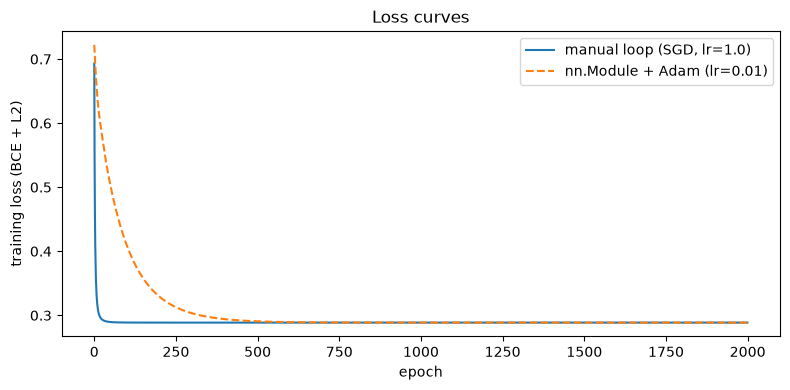

In [203]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(manual_loss_history, label=f"manual loop (SGD, lr={best_lr_manual})")
ax.plot(std_loss_history, linestyle="--", label=f"nn.Module + Adam (lr={best_lr_std})")
ax.set_xlabel("epoch")
ax.set_ylabel("training loss (BCE + L2)")
ax.set_title("Loss curves")
ax.legend()
show_and_save(fig, "04_loss_curves")

## 18. The three models side by side

In [204]:
coef_compare = pd.DataFrame(
    {
        "sklearn": sk_model.coef_[0],
        "manual_torch": w_manual.numpy(),
        "standard_torch": std_model[0].weight.detach().numpy()[0],
    },
    index=FEATURE_NAMES,
)
print(coef_compare.round(4))
print("intercepts:", round(sk_model.intercept_[0], 4), round(b_manual.item(), 4),
      round(std_model[0].bias.item(), 4))

                      sklearn  manual_torch  standard_torch
hour_early             0.0644        0.0639          0.0639
hour_evening          -0.6342       -0.6334         -0.6334
hour_midday           -0.3137       -0.3141         -0.3141
hour_morning           0.0376        0.0370          0.0370
is_weekend            -0.2785       -0.2814         -0.2814
facility_2             0.1836        0.1827          0.1827
facility_3             0.3636        0.3632          0.3632
facility_4             0.0907        0.0906          0.0906
manager_vehicle        0.1070        0.1075          0.1075
reported_zip          -0.1650       -0.1673         -0.1673
distance_missing      -0.0231       -0.0248         -0.0248
distance               0.0244        0.0243          0.0243
user_prev_sessions     0.1188        0.1187          0.1187
user_prev_long_share   0.4264        0.4267          0.4267
user_prev_mean_hours   0.2178        0.2173          0.2173
intercepts: -2.5127 -2.5126 -2.5126


### Coefficients chart

Same comparison as a picture. The three bars for each feature should be practically the same length.

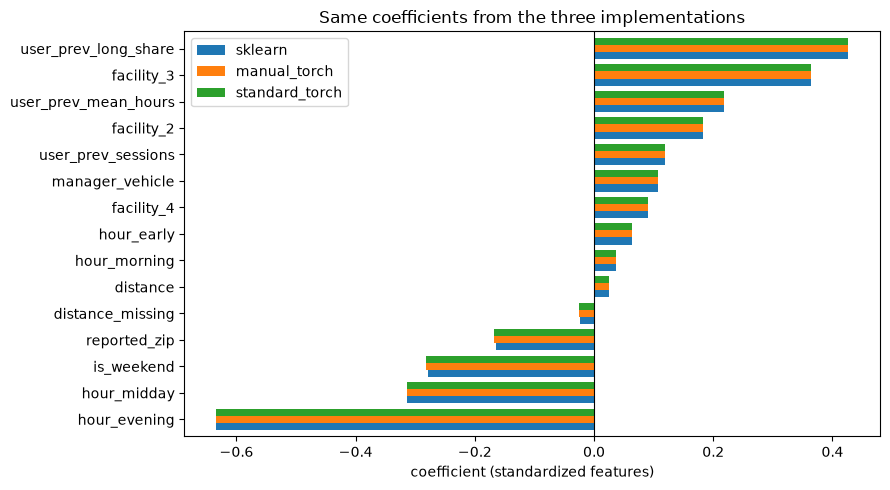

In [205]:
fig, ax = plt.subplots(figsize=(9, 5))
coef_compare.sort_values("sklearn").plot(kind="barh", ax=ax, width=0.8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("coefficient (standardized features)")
ax.set_title("Same coefficients from the three implementations")
show_and_save(fig, "05_coefficients_three_models")

## 19. Business cost and choosing the threshold

A missed long session (false negative) means a another person can't charge, so I count it as 5. An unnecessary reminder (false positive) costs 1. With that ratio, theory says it's worth sending a reminder once the probability goes above 1/(1+5) ≈ 0.17. I try thresholds from 0.01 to 0.90 on validation and keep the cheapest one for each model. Test is still untouched.

In [206]:
COST_FN = 5   # a colleague can't charge: business assumption, see REPORT
COST_FP = 1   # an unnecessary reminder

def business_cost(y_true, probs, threshold):
    alert = probs >= threshold
    fn = int(((~alert) & (y_true == 1)).sum())   # long session, no alert
    fp = int((alert & (y_true == 0)).sum())      # alert, but not a long session
    return COST_FN * fn + COST_FP * fp

def predict_all(X_np, X_t):
    """Probabilities of the three models for the same rows."""
    with torch.no_grad():
        return {
            "sklearn": sk_model.predict_proba(X_np)[:, 1],
            "manual_torch": torch.sigmoid(X_t @ w_manual + b_manual).numpy(),
            "standard_torch": std_model(X_t).squeeze(-1).numpy(),
        }

val_probs = predict_all(X_val, Xva)
test_probs = predict_all(X_test, Xte)

thresholds = np.round(np.arange(0.01, 0.91, 0.01), 2)
chosen_threshold = {}
for name, p in val_probs.items():
    costs = [business_cost(y_val, p, t) for t in thresholds]
    chosen_threshold[name] = float(thresholds[int(np.argmin(costs))])
    print(f"{name:15s} threshold chosen on validation: {chosen_threshold[name]:.2f} (cost {min(costs)})")
print("theoretical threshold 1/(1+5):", round(COST_FP / (COST_FP + COST_FN), 3))

sklearn         threshold chosen on validation: 0.18 (cost 252)
manual_torch    threshold chosen on validation: 0.18 (cost 252)
standard_torch  threshold chosen on validation: 0.18 (cost 252)
theoretical threshold 1/(1+5): 0.167


### Cost vs. threshold

How the cost changes as I move the threshold, with my chosen value, the theoretical one and the default 0.5 marked.

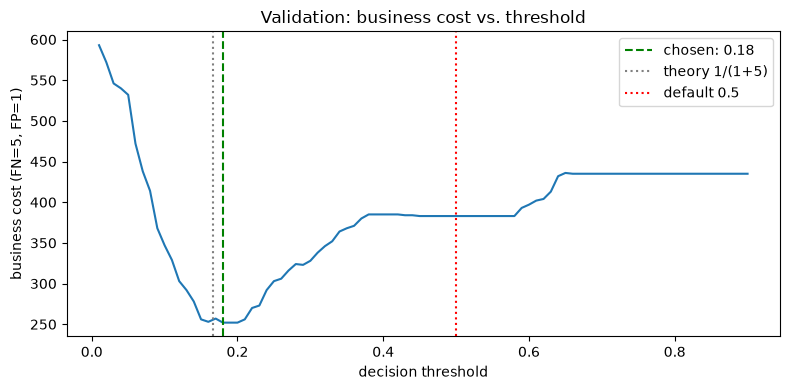

In [207]:
fig, ax = plt.subplots(figsize=(8, 4))
val_costs = [business_cost(y_val, val_probs["sklearn"], t) for t in thresholds]
ax.plot(thresholds, val_costs)
ax.axvline(chosen_threshold["sklearn"], color="green", linestyle="--",
           label=f"chosen: {chosen_threshold['sklearn']:.2f}")
ax.axvline(COST_FP / (COST_FP + COST_FN), color="grey", linestyle=":", label="theory 1/(1+5)")
ax.axvline(0.5, color="red", linestyle=":", label="default 0.5")
ax.set_xlabel("decision threshold")
ax.set_ylabel(f"business cost (FN={COST_FN}, FP={COST_FP})")
ax.set_title("Validation: business cost vs. threshold")
ax.legend()
show_and_save(fig, "06_cost_vs_threshold")

## 20. Final results on the test set

In [208]:
from sklearn.metrics import precision_score, recall_score

cost_alert_nobody = COST_FN * int(y_test.sum())
cost_alert_everyone = COST_FP * int((y_test == 0).sum())

rows = [{
    "model": "naive baseline",
    **evaluate_probs(y_test, np.full(len(y_test), baseline_prob)),
    "threshold": None, "recall": 0.0, "precision": None,
    "business_cost": min(cost_alert_nobody, cost_alert_everyone),
}]
for name, p in test_probs.items():
    t = chosen_threshold[name]
    pred = (p >= t).astype(int)
    rows.append({
        "model": name, **evaluate_probs(y_test, p), "threshold": t,
        "recall": recall_score(y_test, pred), "precision": precision_score(y_test, pred),
        "business_cost": business_cost(y_test, p, t),
    })
results_test = pd.DataFrame(rows)
print(results_test.round(3).to_string(index=False))

# How different are the predicted probabilities?
print("max |prob - sklearn prob|:",
      {k: round(float(np.abs(v - test_probs["sklearn"]).max()), 4) for k, v in test_probs.items()})

         model  log_loss  roc_auc  pr_auc  threshold  recall  precision  business_cost
naive baseline     0.364    0.500   0.118        NaN   0.000        NaN            400
       sklearn     0.301    0.791   0.346       0.18   0.638      0.389            225
  manual_torch     0.301    0.791   0.346       0.18   0.638      0.389            225
standard_torch     0.301    0.791   0.346       0.18   0.638      0.389            225
max |prob - sklearn prob|: {'sklearn': 0.0, 'manual_torch': 0.0008, 'standard_torch': 0.0008}


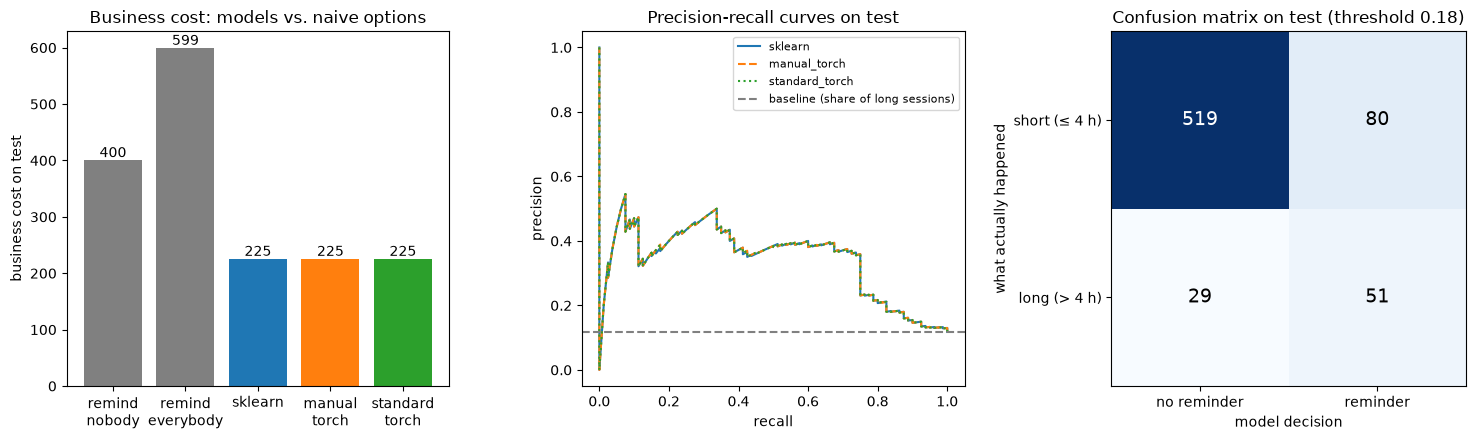

In [209]:
from sklearn.metrics import precision_recall_curve, confusion_matrix

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# 1. Business cost
cost_labels = ["remind\nnobody", "remind\neverybody", "sklearn", "manual\ntorch", "standard\ntorch"]
cost_values = [cost_alert_nobody, cost_alert_everyone] + [
    business_cost(y_test, p, chosen_threshold[name]) for name, p in test_probs.items()]
bars = axes[0].bar(cost_labels, cost_values, color=["grey", "grey", "tab:blue", "tab:orange", "tab:green"])
axes[0].bar_label(bars)
axes[0].set_ylabel("business cost on test")
axes[0].set_title("Business cost: models vs. naive options")

# 2. Precision-recall curves
for (name, p), style in zip(test_probs.items(), ["-", "--", ":"]):
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[1].plot(rec, prec, linestyle=style, label=name)
axes[1].axhline(y_test.mean(), color="grey", linestyle="--", label="baseline (share of long sessions)")
axes[1].set_xlabel("recall")
axes[1].set_ylabel("precision")
axes[1].set_title("Precision-recall curves on test")
axes[1].legend(fontsize=8)

# 3. Confusion matrix at the chosen threshold (the three models are the same, so sklearn)
pred = (test_probs["sklearn"] >= chosen_threshold["sklearn"]).astype(int)
cm = confusion_matrix(y_test, pred)
axes[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        axes[2].text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[2].set_xticks([0, 1], ["no reminder", "reminder"])
axes[2].set_yticks([0, 1], ["short (≤ 4 h)", "long (> 4 h)"])
axes[2].set_xlabel("model decision")
axes[2].set_ylabel("what actually happened")
axes[2].set_title(f"Confusion matrix on test (threshold {chosen_threshold['sklearn']:.2f})")

show_and_save(fig, "07_test_results")

- **The baseline costs 400.** It can't tell sessions apart, so its best option is to remind nobody and miss all 80 long sessions (80 × 5). Reminding everybody would cost even more (599).
- **The model costs 225, about 44% less.** It catches 51 of the 80 long sessions (recall 0.64) and misses 29. About 4 out of every 10 reminders go to someone who really was going to block the charger (precision 0.39), so roughly 80 reminders were unnecessary. That's the trade-off I chose on purpose: an extra reminder is cheap, another person who can't charge isn't. Cost check: 29 × 5 + 80 × 1 = 225.
- **PR AUC goes from 0.12 to 0.35**, about three times better than the baseline, and ROC AUC is 0.79.
- **Test is a bit worse than validation** (PR AUC 0.35 vs 0.39). That's expected: test is a later month the model never saw, which is exactly the point of splitting by time.
- **The three implementations give the same results.** Their probabilities differ by at most 0.0008, which is too small to change any decision at a 0.18 threshold. That makes sense because all three minimise the same function (BCE + the same L2 penalty) on the same data.

## 21. Which features actually help?

I remove one group of features at a time, retrain with scikit-learn and check validation. If the model gets worse without a group, that group was pulling its weight. If nothing changes, it wasn't adding much.

In [210]:
def val_score_without(drop_group=None):
    cols = [i for i, f in enumerate(FEATURE_NAMES)
            if drop_group is None or f not in FEATURE_GROUPS[drop_group]]
    m = LogisticRegression(C=best_C, max_iter=1000).fit(X_train[:, cols], y_train)
    p = m.predict_proba(X_val[:, cols])[:, 1]
    return {
        "removed": drop_group or "(none: all features)",
        "val_pr_auc": average_precision_score(y_val, p),
        "val_best_cost": min(business_cost(y_val, p, t) for t in thresholds),
    }

ablation = pd.DataFrame([val_score_without(None)] + [val_score_without(g) for g in FEATURE_GROUPS])
print(ablation.round(3).to_string(index=False))

             removed  val_pr_auc  val_best_cost
(none: all features)       0.389            252
                time       0.316            277
             profile       0.387            249
            distance       0.391            250
             history       0.326            324


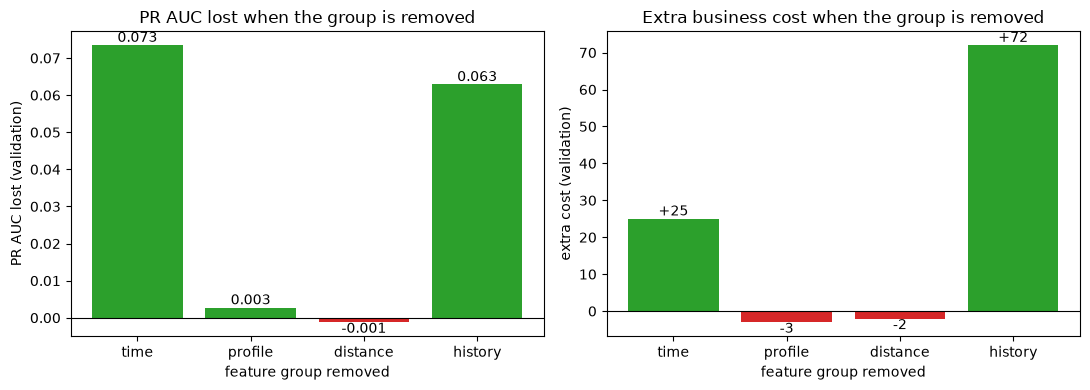

In [211]:
full = ablation.iloc[0]
drops = ablation.iloc[1:].set_index("removed")
pr_auc_lost = full["val_pr_auc"] - drops["val_pr_auc"]      # > 0: the group was helping
extra_cost = drops["val_best_cost"] - full["val_best_cost"]  # > 0: the group was helping

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, values, title in [
    (axes[0], pr_auc_lost, "PR AUC lost when the group is removed"),
    (axes[1], extra_cost, "Extra business cost when the group is removed"),
]:
    colors = ["tab:green" if v > 0 else "tab:red" for v in values]
    bars = ax.bar(values.index, values, color=colors)
    ax.bar_label(bars, fmt="%.3f" if values is pr_auc_lost else "%+.0f")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("feature group removed")
axes[0].set_ylabel("PR AUC lost (validation)")
axes[1].set_ylabel("extra cost (validation)")
show_and_save(fig, "08_feature_group_ablation")

- **History and start time are what really matter.** Without the driver's history the cost goes from 252 to 324, and without the start time to 277.
- **Profile and distance add basically nothing.** Removing them changes the cost by 2–3 points, which is noise. I expected the facility type to help a lot, since facility 4 has many more long sessions than the others. My explanation is that the history already captures it: people who charge at facility 4 already have a history of long sessions, so the model doesn't need both.
- **I kept them anyway.** The difference is too small to be meaningful on one month of validation data, and removing features based on such small changes would be tuning to noise.

In [212]:
import json
raw_cols = df[["created", "split", "target", "chargeTimeHrs", "startTime",
               "weekday", "facilityType", "distance"]].rename(columns={"distance": "distance_raw"})
dashboard_df = pd.concat([raw_cols.reset_index(drop=True), X_all.reset_index(drop=True)], axis=1)
dashboard_df.to_csv(ARTIFACTS_DIR / "dashboard_data.csv", index=False)
joblib.dump(scaler, ARTIFACTS_DIR / "scaler.joblib")
results_test.to_csv(ARTIFACTS_DIR / "test_results.csv", index=False)
ablation.to_csv(ARTIFACTS_DIR / "ablation.csv", index=False)
coef_compare.to_csv(ARTIFACTS_DIR / "coefficients.csv")

metadata = {
    "feature_names": FEATURE_NAMES, "feature_groups": FEATURE_GROUPS,
    "cost_fn": COST_FN, "cost_fp": COST_FP, "chosen_threshold": chosen_threshold,
    "baseline_prob": float(baseline_prob), "long_session_hours": LONG_SESSION_HOURS,
    "best_C": best_C, "lr_manual": best_lr_manual, "lr_standard": best_lr_std,
    "loss_history": {"manual_torch": manual_loss_history, "standard_torch": std_loss_history},
}
with open(ARTIFACTS_DIR / "metadata.json", "w") as f:
    json.dump(metadata, f)
print("saved:", sorted(p.name for p in ARTIFACTS_DIR.iterdir()))

saved: ['ablation.csv', 'coefficients.csv', 'dashboard_data.csv', 'figures', 'manual_torch_model.pt', 'metadata.json', 'scaler.joblib', 'sklearn_model.joblib', 'standard_torch_model.pt', 'test_results.csv']
